# code_004 · Generate scenarios, simulate forward, and infer what is identifiable

**Book:** Chapter 1, section 1.3. **Purpose:** executable concept experiments, not a complete estimator hyperparameter course. All data and helper definitions are inside this notebook. Synthetic values are invented for teaching and provide no engineering validation.

Use the repository [quickstart](../README.md) and pinned environment. Restart the kernel and run all cells in order. Verified target: CPython 3.14.3 and scikit-learn 1.9.0, CPU only; no files, downloads, API keys or project imports are needed during execution. Allow a minute for execution plus time to reason through the prompts. Actual time, environment and checks are recorded at the end and in the [Chapter 1 execution report](../CHAPTER_01_EXECUTION.md).

Read each prediction prompt before running its experiment. Controls are identified as task, data-generation, model or decision controls; they are not interchangeable. The [stable directory](../CODE_EXAMPLES.md#code_004) links this example to the manuscript.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=101
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
assert sklearn.__version__=='1.9.0','Use the verified pinned environment.'
print(VERSIONS);print('CPU:',platform.system(),platform.machine())
plt.rcParams.update({'figure.dpi':100,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64


<a id="generation"></a>
## Generate a scenario, not a prediction target

A generator supplies plausible candidate observations under an assumed distribution. We compare two simple baselines: resampling observed temperature/load *pairs*, and resampling each column independently. Pair resampling retains observed pairings; independent columns can destroy dependence even if their individual ranges look convincing. This is bootstrap scenario generation, not a newly trained diffusion model or a claim that the scenarios cover unseen extremes. No private records are involved.

**Predict:** should marginal histograms alone distinguish the two generators? Temperature is in degrees Celsius and load in newtons; the relationship is invented. Change sample size as a generation control and inspect correlation and the joint plot, not only column ranges.


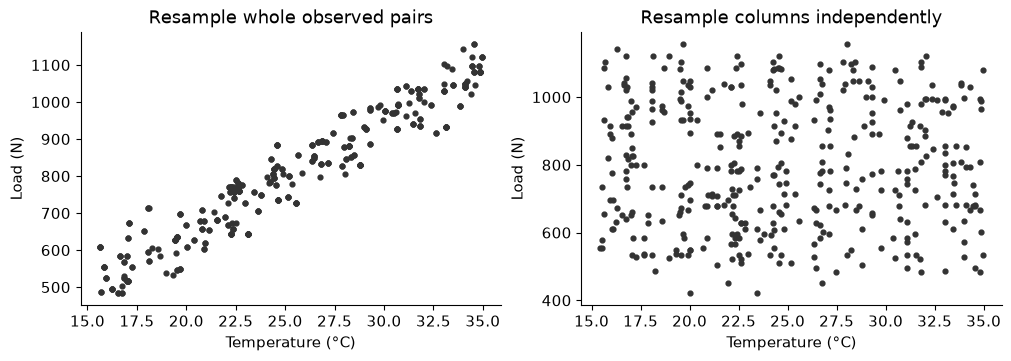

Joint correlations: {'reference': 0.9643418090124722, 'paired': 0.9572999116051417, 'independent': 0.0006441985146437534}


In [2]:
rng=np.random.default_rng(SEED)
temperature=rng.uniform(15,35,200)
load=500+30*(temperature-15)+rng.normal(0,50,200)
observed=np.c_[temperature,load]
paired=observed[rng.integers(0,len(observed),400)]
independent=np.c_[rng.choice(temperature,400),rng.choice(load,400)]
correlations={name:float(np.corrcoef(data.T)[0,1]) for name,data in [('reference',observed),('paired',paired),('independent',independent)]}
assert (paired[:,1]>0).all() and set(map(tuple,paired))<=set(map(tuple,observed))
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
for a,data,title in zip(ax,[paired,independent],['Resample whole observed pairs','Resample columns independently']):
 a.scatter(*data.T,s=12,color='.2');a.set(title=title,xlabel='Temperature (°C)',ylabel='Load (N)')
plt.show();print('Joint correlations:',correlations);RESULTS['scenario_correlations']=correlations


<a id="forward"></a>
## A declared physical model and a learned surrogate

For a static ideal linear spring, the restoring force is opposite displacement: Fs = -k*u. An applied balancing force has magnitude P = k*u, so u = P/k. For two ideal massless springs in series, the same axial force passes through both and displacements add: u = P*(1/k1 + 1/k2). Stiffness is in N/m, force in N, and displacement in m. These assumptions exclude dynamics, nonlinear response, damage evolution and arbitrary frame mechanics. Source for the spring law: [OpenStax University Physics, 15.1](https://openstax.org/books/university-physics-volume-1/pages/15-1-simple-harmonic-motion); the series expression follows by adding the two displacements.

A simulator evaluates the stated rule. A surrogate learns an approximation to simulator input/output pairs. On this one-dimensional linear family, fitting compliance with zero intercept is enough; this is a transparent baseline, not a neural operator. The held-out forces below diagnose the already fixed fit, not a tuned model. **Predict:** what are the units of the fitted slope?


In [3]:
from sklearn.linear_model import LinearRegression
k1,k2=1e6,2e6
true_compliance=1/k1+1/k2
force_train=np.array([500.,1000.,1500.,2000.])
u_exact=force_train*true_compliance
u_measured=u_exact+rng.normal(0,2e-5,len(force_train)) # 20 micrometre noise SD
surrogate=LinearRegression(fit_intercept=False).fit(force_train[:,None],u_measured)
compliance_est=float(surrogate.coef_[0]);assert compliance_est>0
force_check=np.array([600.,1200.,1800.])
u_check=surrogate.predict(force_check[:,None])
assert np.isclose(1000*true_compliance,.0015)
display(pd.DataFrame({'P_N':force_check,'simulator_u_mm':1000*force_check*true_compliance,'surrogate_u_mm':1000*u_check}))
print('Fitted compliance (m/N):',compliance_est,'| equivalent stiffness (N/m):',1/compliance_est)
RESULTS['compliance_estimate_m_per_N']=compliance_est
RESULTS['heldout_surrogate_MAE_mm']=float(np.mean(np.abs(u_check-force_check*true_compliance))*1000)


,P_N,simulator_u_mm,surrogate_u_mm
0,600.0,0.9,0.900551
1,1200.0,1.8,1.801101
2,1800.0,2.7,2.701652


Fitted compliance (m/N): 1.5009175916631182e-06 | equivalent stiffness (N/m): 666259.0974711225


<a id="inverse"></a>
## Inverse ambiguity survives additional load cases

Endpoint displacement measures the sum of the two compliances. It does not identify each stiffness separately. The pairs (1,2) million N/m and (0.8,4) million N/m have exactly the same total compliance, so all endpoint force/displacement observations agree under this model. Additional endpoint loads reduce noise about the effective compliance but cannot distinguish those two pairs. A low fitting loss does not resolve this structural ambiguity.

An internal displacement measurement across the first spring, or trusted knowledge of one stiffness, can add independent information. Assuming two equal springs would also pick a solution, but that solution would come from the assumption rather than the endpoint data. **Predict:** will removing measurement noise make k1 and k2 uniquely identifiable? Compare the exact curves and the different internal displacements.


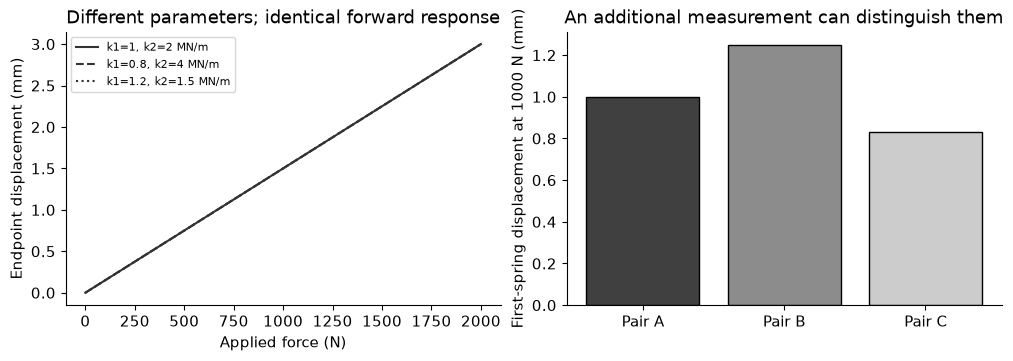

In [4]:
pairs=[(1e6,2e6),(.8e6,4e6),(1.2e6,1.5e6)]
forces=np.linspace(0,2000,80)
curves=np.array([forces*(1/a+1/b) for a,b in pairs])
assert np.allclose(curves,curves[0])
internal_at_1000=[1000/a for a,b in pairs]
assert len(set(internal_at_1000))==3
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
for (a,b),curve,style in zip(pairs,curves,['-','--',':']):
 ax[0].plot(forces,1000*curve,style,label=f'k1={a/1e6:g}, k2={b/1e6:g} MN/m',color='.2')
ax[0].set(xlabel='Applied force (N)',ylabel='Endpoint displacement (mm)',title='Different parameters; identical forward response');ax[0].legend(fontsize=8)
ax[1].bar(range(3),np.array(internal_at_1000)*1000,color=['.25','.55','.8'],edgecolor='black')
ax[1].set_xticks(range(3),['Pair A','Pair B','Pair C']);ax[1].set(ylabel='First-spring displacement at 1000 N (mm)',title='An additional measurement can distinguish them')
plt.show()
RESULTS['identical_endpoint_pairs']=[list(v) for v in pairs]
RESULTS['distinct_internal_displacements_mm']=(np.array(internal_at_1000)*1000).tolist()


## Exercises and validity checks

1. Verify the series equation by checking units and adding the two elongations; explain the sign difference between restoring and applied force.
2. Repeat noisy calibration with five predeclared seeds and report the spread of *effective* stiffness, not invented recovery of both individual values.
3. Add an internal sensor. Recover k1 from its displacement and infer k2 from the remaining compliance; check positivity and sensitivity to noise.
4. Generate loads outside the reference range and state why successful execution is not evidence of validity there.
5. Compare fixed and uncertain stiffness assumptions when generating displacement scenarios. Which correlations and constraints should a generator preserve?

**Optional hint:** more data about the same uninformative combination do not replace a different measurement. A prior or regularizer can choose among ambiguous solutions, but the choice must be reported as assumption-dependent.


## Interpretation, limits and next steps

The printed tables and figures are observations from this executed synthetic experiment. Describe the mechanism they demonstrate before comparing individual numbers. Fixed seeds make the teaching run reproducible; they do not establish performance in a new population. No deployment or physical validity guarantee follows from passing these checks. For model-specific controls, use the official documentation and the later model chapters; [code_001](../CODE_EXAMPLES.md#code_001) is a full decision-tree parameter laboratory.

**Troubleshooting:** a version assertion means the selected kernel differs from the pinned environment. Restart and run all cells rather than borrowing state from a different notebook. Missing or repeated timestamps require an explicit observation policy, not a silent row reorder. When adapting an experiment, record its new assumptions, selection rule and untouched assessment evidence. Initial package installation may use the internet; these cells do not.


In [5]:
EXECUTION_SUMMARY={'example_id':'code_004','versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU',
 'seed':SEED,'concepts_demonstrated':['scenario generation and dependence', 'Hooke-law units and assumptions', 'forward simulation', 'surrogate approximation', 'inverse effective compliance', 'structural non-identifiability', 'additional measurements'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:',json.dumps(EXECUTION_SUMMARY,sort_keys=True))


EXECUTION_SUMMARY_JSON: {"concepts_demonstrated": ["scenario generation and dependence", "Hooke-law units and assumptions", "forward simulation", "surrogate approximation", "inverse effective compliance", "structural non-identifiability", "additional measurements"], "elapsed_seconds": 0.298, "example_id": "code_004", "hardware": "Darwin arm64 CPU", "results": {"compliance_estimate_m_per_N": 1.5009175916631182e-06, "distinct_internal_displacements_mm": [1.0, 1.25, 0.8333333333333334], "heldout_surrogate_MAE_mm": 0.001101109995741923, "identical_endpoint_pairs": [[1000000.0, 2000000.0], [800000.0, 4000000.0], [1200000.0, 1500000.0]], "scenario_correlations": {"independent": 0.0006441985146437534, "paired": 0.9572999116051417, "reference": 0.9643418090124722}}, "seed": 101, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
